# 02 · Retrieval lexical com BM25

Objetivo: construir e avaliar o baseline de retrieval, um índice BM25 sobre o texto dos produtos, conforme o protocolo de [docs/EVALUATION.md](../docs/EVALUATION.md).

Regras deste notebook:
- O **conjunto de teste não é usado**: nem os `label`, nem o texto das queries de teste. As análises de queries usam só treino e validação.
- O catálogo (`product.csv`) é o mesmo para todas as partes e não tem `label`, então é analisado inteiro.
- As conclusões declaram as **suposições** e, para cada **escolha**, as alternativas.

Etapas:
1. O texto que o BM25 vai indexar
2. Índice e busca *(próxima etapa)*
3. Avaliação na validação *(próxima etapa)*

## Termos usados

- **Token:** uma palavra do texto, obtida removendo acentos, passando para minúsculas e quebrando em tudo que não é letra ou dígito (`wands_search.text.tokenize`). Aqui, ao contrário da EDA, **as repetições contam**, porque o BM25 conta quantas vezes cada palavra aparece. Exemplo: `'Fawkes 36" Blue-Vanity'` dá `fawkes`, `36`, `blue`, `vanity`.
- **Campo único:** o texto de `product_name`, `product_class`, `category_hierarchy`, `product_description` e dos valores de `product_features`, emendados nessa ordem. É o texto do índice do baseline.
- **Vocabulário:** o conjunto de tokens distintos de um texto ou de um catálogo.

## Setup

In [1]:
import numpy as np
import pandas as pd

from wands_search import data, text

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)

products = data.load_products()
queries = data.load_queries()
query_split = pd.read_csv("../splits/query_split.csv")

print("pandas", pd.__version__, "| numpy", np.__version__)
print("products:", len(products), "| queries:", len(queries))

pandas 3.1.1 | numpy 2.5.4
products: 42994 | queries: 480


## Etapa 1 · O texto que o BM25 vai indexar

Antes de construir o índice, olhamos o que entra nele: o texto de cada campo, depois de `wands_search.text.product_field_texts`, e os tokens que saem de `tokenize`. O processamento é o mesmo para queries e produtos.

### 1.1 Um produto, campo a campo

`product_features` entra só com os valores, sem as chaves (`color : caramel` vira `caramel`), como proposto na EDA (Etapa 2.5).

In [2]:
field_texts = text.product_field_texts(products)
single_text = text.single_field_text(field_texts)

example_id = 0
example = pd.DataFrame({
    "text": field_texts.loc[example_id].str.slice(0, 120),
    "n_tokens": field_texts.loc[example_id].map(lambda value: len(text.tokenize(value))),
})
display(example)
print("single field, first 40 tokens:", text.tokenize(single_text.loc[example_id])[:40])

,text,n_tokens
product_name,solid wood platform bed,4
product_class,Beds,1
category_hierarchy,Furniture / Bedroom Furniture / Beds & Headboards / Beds / Twin Beds,8
product_description,"good , deep sleep can be quite difficult to have in this busy age . fortunately , there ’ s an antidote to such a pr...",175
product_features,64.7 modern made in viet nam slat 25.35 500 120 77.9 full assembly needed 78.7 rubberwood 12 39.6 rectangular acacia...,116


single field, first 40 tokens: ['solid', 'wood', 'platform', 'bed', 'beds', 'furniture', 'bedroom', 'furniture', 'beds', 'headboards', 'beds', 'twin', 'beds', 'good', 'deep', 'sleep', 'can', 'be', 'quite', 'difficult', 'to', 'have', 'in', 'this', 'busy', 'age', 'fortunately', 'there', 's', 'an', 'antidote', 'to', 'such', 'a', 'problem', 'a', 'nice', 'quality', 'bed', 'frame']


**Conclusões**

- **No campo único, `product_name` é uma parte pequena do texto:** no produto 0, ele tem 4 dos 304 tokens. `product_description` tem 175, e `product_features` tem 116.
- **Sem as chaves, os valores de `product_features` perdem o contexto:** `64.7`, `25.35` e `500` são medidas, mas no texto viram só números; `full assembly needed` aparece sem dizer a que se refere.
- **O apóstrofo tipográfico (`’`) quebra palavras:** `there ’ s` vira `there` e `s`. O mesmo acontece com o apóstrofo comum. Não medimos quantas vezes isso ocorre; como acontece do mesmo jeito nas queries, o efeito esperado é pequeno.

**Suposições**
- O produto 0 serve só de exemplo; os números do catálogo inteiro estão em 1.2.

### 1.2 Tamanho de cada campo, em tokens

Medimos quantos tokens cada campo tem por produto e quanto cada campo representa do total de tokens do campo único. No BM25, um campo mais longo traz mais ocorrências de palavras e mais tamanho de texto, então pesa mais na nota do campo único.

In [3]:
token_lists = {field: field_texts[field].map(text.tokenize) for field in text.SEARCH_FIELDS}
token_counts = pd.DataFrame({field: tokens.map(len) for field, tokens in token_lists.items()})

field_sizes = pd.DataFrame({
    "empty_pct": (token_counts == 0).mean() * 100,
    "median": token_counts.median(),
    "p95": token_counts.quantile(0.95),
    "mean": token_counts.mean(),
    "share_of_single_field_pct": token_counts.sum() / token_counts.sum().sum() * 100,
}).round(1)
display(field_sizes)

single_counts = token_counts.sum(axis=1)
print("single field tokens per product: median", single_counts.median(),
      "| p95", single_counts.quantile(0.95), "| max", single_counts.max())

,empty_pct,median,p95,mean,share_of_single_field_pct
product_name,0.0,6.0,13.0,6.5,3.9
product_class,6.6,2.0,4.0,2.2,1.3
category_hierarchy,3.6,8.0,15.0,8.3,4.9
product_description,14.0,60.0,160.0,65.2,38.9
product_features,0.0,78.0,165.0,85.3,50.9


single field tokens per product: median 159.0 | p95 300.0 | max 1465


**Conclusões**

- **`product_features` e `product_description` são 89,8% dos tokens do campo único** (50,9% e 38,9%). `product_name` é 3,9%, `category_hierarchy` 4,9% e `product_class` 1,3%.
- **Os campos variam muito de tamanho:** a mediana é 6 tokens em `product_name` e 78 em `product_features`. O campo único tem mediana de 159 tokens por produto, p95 de 300 e máximo de 1.465.
- **14,0% dos produtos não têm `product_description`:** o campo único deles é mais curto, e a normalização de tamanho do BM25 (`b`) favorece textos curtos. Não medimos o efeito disso na nota.

**O que isso muda para o BM25**
- No campo único, uma palavra da query encontrada só em `product_name` conta como qualquer outra ocorrência, num texto que é quase todo descrição e features. É o principal motivo para testar o retrieval por campo (soma ponderada ou BM25F) no ajuste.

**Escolhas e alternativas**
- **Escolha (baseline):** campo único com os cinco campos, sem pesos. **Alternativas:** retrieval por campo, com pesos ajustados no treino; repetir `product_name` no texto para aumentar o peso dele; deixar `product_features` ou `product_description` de fora. Todas a testar no ajuste, no treino.

### 1.3 O que há nos valores de `product_features`

Sem as chaves, muitos valores de `product_features` são `yes`, `no` ou números (`footboard : no` vira só `no`). Medimos quanto dos tokens desse campo é desse tipo, porque são tokens que quase nunca coincidem com uma query, mas aumentam o tamanho do texto.

In [4]:
feature_tokens = pd.Series([token for tokens in token_lists["product_features"] for token in tokens])

def token_kind(token: str) -> str:
    if token in {"yes", "no"}:
        return "yes / no"
    if token.isdigit():
        return "number"
    return "other"

kinds = feature_tokens.map(token_kind).value_counts(normalize=True).mul(100).round(1)
display(kinds.rename("pct_of_product_features_tokens").to_frame())
display(feature_tokens.value_counts().head(15).rename("count").to_frame())

,pct_of_product_features_tokens
other,50.2
yes / no,31.4
number,18.4


,count
no,788090
yes,363538
1,62542
5,53383
use,52566
wood,48644
residential,43096
2,38984
distressing,25190
china,24539


**Conclusões**

- **Metade dos tokens de `product_features` é `yes`, `no` ou número:** 31,4% são `yes` ou `no` e 18,4% são números. Como `product_features` é 50,9% do campo único, esses tokens são cerca de um quarto do texto indexado.
- **`no` é o token mais comum do campo, com 788.090 ocorrências, e `yes` o segundo, com 363.538.** Nenhuma query de treino ou validação tem `yes` ou `no`, então esses tokens não ajudam a encontrar nada.
- **Eles mudam a nota mesmo assim,** porque aumentam o tamanho do texto, e o BM25 dá nota menor a textos longos (`b`). Um produto com muitas chaves `yes`/`no` fica em desvantagem, sem relação com a query.
- **Números podem coincidir com a query por acaso:** 29 das 384 queries de treino e validação têm um token só de número, como `36` ou `48`. Em `product_features`, o mesmo número pode ser outra medida, como um peso.

**Suposições**
- Tratamos `yes` e `no` como sem sentido sozinhos. Junto da chave, como em `headboard : yes`, eles têm informação, que a escolha de usar só os valores perde.

**Escolhas e alternativas**
- **Escolha (baseline):** manter os valores como estão, como proposto na EDA. **Alternativas a testar no ajuste:** remover os valores `yes`/`no`; trocar `chave : yes` pela chave (`headboard : yes` vira `headboard`); remover os valores só numéricos; deixar `product_features` fora do campo único e usá-lo só como feature do reranker.

### 1.4 As queries de treino e validação contra o vocabulário do catálogo

Um token da query que não existe no catálogo nunca contribui para a nota do BM25. Uma query sem nenhum token no catálogo não recupera nenhum produto.

Usamos só as queries de treino e validação. As queries de teste ficam de fora para que nada do que vemos no texto delas influencie as escolhas do sistema.

In [5]:
dev_queries = queries.merge(query_split, on="query_id")
dev_queries = dev_queries[dev_queries["split"].isin(["train", "validation"])].copy()
dev_queries["tokens"] = dev_queries["query"].map(text.tokenize)

catalog_vocabulary = {token for tokens in token_lists.values() for token_list in tokens for token in token_list}
print("catalog vocabulary (single field):", len(catalog_vocabulary))
print("queries (train + validation):", len(dev_queries), "| by split:", dev_queries["split"].value_counts().to_dict())
print("tokens per query:", dev_queries["tokens"].map(len).describe()[["min", "50%", "mean", "max"]].to_dict())

dev_queries["missing_tokens"] = dev_queries["tokens"].map(lambda tokens: [t for t in tokens if t not in catalog_vocabulary])
with_missing = dev_queries[dev_queries["missing_tokens"].map(len) > 0]
print("queries with at least one token outside the catalog:", len(with_missing))
display(with_missing[["query_id", "split", "query", "missing_tokens"]].sort_values("query_id"))

no_token = dev_queries[dev_queries["tokens"].map(lambda tokens: not set(tokens) & catalog_vocabulary)]
print("queries with no token in the catalog:")
display(no_token[["query_id", "split", "query"]])

catalog vocabulary (single field): 54416
queries (train + validation): 384 | by split: {'train': 287, 'validation': 97}
tokens per query: {'min': 1.0, '50%': 3.0, 'mean': 3.4270833333333335, 'max': 11.0}
queries with at least one token outside the catalog: 26


,query_id,split,query,missing_tokens
20,20,train,foutains with brick look,[foutains]
23,23,train,stoneford end tables white and wood,[stoneford]
62,62,train,7qt slow cooker,[7qt]
77,77,train,sancroft armchair,[sancroft]
87,87,train,vlad modular sectional,[vlad]
90,90,train,filaret outdoor sofa,[filaret]
98,98,validation,gracie oaks 62 oller 14 ceiling fan,[oller]
178,179,train,promo codes or discounts,"[promo, discounts]"
189,191,train,biycicle plant stands,[biycicle]
202,205,train,ines shag rug w003096809,[w003096809]


queries with no token in the catalog:


,query_id,split,query
376,383,validation,minnestrista


**Conclusões**

- **26 das 384 queries de treino e validação têm algum token que não existe no catálogo.** Pela nossa leitura (não medida), eles se dividem em:
  - erros de digitação: `foutains`, `biycicle`, `ligth`, `desins`, `doning`, `pedistole`, `lsmp`;
  - nomes de marca ou de produto que não estão no catálogo: `stoneford`, `sancroft`, `vlad`, `filaret`, `candace`, `donaldson`, `tressler`, `fortunat`, `maryford`, `oller`, `trinaic`;
  - palavras juntas: `7qt` (o catálogo escreve `7 qt`, em 9 valores de `product_name`) e `roomtables`;
  - códigos e termos fora do catálogo: `w003096809`, `5995`, `lowes`, `promo`, `discounts`, `tye`.
- **Só uma query não tem nenhum token no catálogo:** `minnestrista` (`query_id` 383, validação). O BM25 não vai retornar nenhum produto para ela, e as métricas dela serão 0.
- **Nas outras 25, o BM25 ainda funciona com os tokens restantes:** em `ligth bulb`, só `bulb` conta.
- As queries têm mediana de 3 tokens e no máximo 11.

**Suposições**
- A divisão dos tokens em erros de digitação, marcas e palavras juntas é uma leitura nossa, não uma medição.

**Escolhas e alternativas**
- **Escolha (baseline):** nenhuma correção de query. **Alternativas:** correção ortográfica contra o vocabulário do catálogo; tokens de subpalavras ou de caracteres (n-gramas de caracteres), que encontram `ligth` perto de `light`; o retrieval semântico, que pode tolerar parte desses erros. A primeira delas só se justifica se a análise de erros mostrar perda relevante nessas queries.

## Resumo da Etapa 1

- O campo único é quase todo `product_features` e `product_description` (89,8% dos tokens), e um quarto dele são tokens `yes`, `no` e números de `product_features`, que nenhuma query de treino ou validação usa.
- O baseline fica como planejado (campo único, sem stemming, sem limpeza de `product_features`), para termos uma referência medida. As variantes acima são testadas no ajuste, no treino.
- Uma query de validação (`minnestrista`) não tem nenhum token no catálogo e vai ter nota 0 em qualquer sistema lexical.

**Próximo passo:** Etapa 2, índice `bm25s` do campo único e busca, com o tratamento de entradas inválidas.

## Etapa 2 · Índice e busca

Construímos o índice BM25 do campo único com `wands_search.retrieval` (biblioteca `bm25s`), com os parâmetros do baseline: `k1 = 1.2`, `b = 0.75` e a variante `lucene`, padrão do `bm25s`. A variante `lucene` não tem o fator (`k1` + 1) no numerador da fórmula; isso multiplica todas as notas pela mesma constante e não muda a ordem. `k1` e `b` são ajustados depois, no treino.

A busca devolve os produtos com nota positiva, ordenados pela nota; empates são desfeitos pelo menor `product_id`, para que o resultado seja sempre o mesmo.

### 2.1 Custo de indexação

Medimos o tempo de cada passo e o tamanho do índice em memória. O índice guarda uma nota pronta por par (token, produto) em que o token aparece, numa matriz esparsa.

In [6]:
import time

import bm25s

from wands_search import retrieval

print("bm25s", bm25s.__version__, "| params:", retrieval.BM25_K1, retrieval.BM25_B, retrieval.BM25_METHOD)

timings = {}
start = time.perf_counter()
build_texts = text.single_field_text(text.product_field_texts(products))
timings["field texts"] = time.perf_counter() - start

start = time.perf_counter()
build_tokens = build_texts.map(text.tokenize)
timings["tokenization"] = time.perf_counter() - start

start = time.perf_counter()
index = retrieval.BM25Index(build_tokens.index.to_list(), build_tokens.to_list())
timings["bm25s index"] = time.perf_counter() - start

timings["total"] = sum(timings.values())
display(pd.Series(timings, name="seconds").round(2).to_frame())
print("vocabulary (with the empty token of bm25s):", index.vocabulary_size)
print("stored (token, product) pairs:", int(build_tokens.map(lambda tokens: len(set(tokens))).sum()))
print(f"index memory: {index.index_bytes / 1e6:.1f} MB")

bm25s

 0.3.16 | params: 1.2 0.75 lucene


,seconds
field texts,4.21
tokenization,8.66
bm25s index,9.03
total,21.90


vocabulary (with the empty token of bm25s): 54417


stored (token, product) pairs: 4150707
index memory: 33.6 MB


**Conclusões**

- **A indexação do campo único leva cerca de 10 a 12 s nesta máquina:** a tabela acima mostra a última execução. A tokenização em Python é o passo mais lento, seguida da construção do índice pelo `bm25s`. Os tempos mudam a cada execução.
- **O índice guarda 4.150.707 pares (token, produto) e ocupa 33,6 MB em memória.** O vocabulário tem 54.417 tokens: os 54.416 da Etapa 1.4 mais o token vazio que o `bm25s` adiciona.
- **Os índices por campo, para o reranker, vão somar tempo e memória.** Não medimos ainda; serão medidos quando forem construídos.

**Suposições**
- Os tempos são de uma única máquina (mostrada em 2.4), sem controle de outras cargas; servem como ordem de grandeza, não como medida exata.

### 2.2 Dois exemplos de treino

Olhamos os 10 primeiros resultados de duas queries de **treino**, com o `label` de cada produto (`unjudged` = sem `label` para a query). Para cada produto, indicamos em quais campos aparece algum token da query, para ver de onde vem a nota.

- `tye dye duvet cover`: `tye` não existe no catálogo (Etapa 1.4).
- `pedistole sink`: `pedistole` é um erro de digitação de *pedestal*.

In [7]:
labels = data.deduplicate_labels(data.load_labels())

def explain_top(query_text: str, k: int = 10) -> pd.DataFrame:
    query_row = dev_queries[dev_queries["query"] == query_text].iloc[0]
    assert query_row["split"] == "train"
    query_tokens = set(text.tokenize(query_text))
    result = index.search(query_text, k=k)
    query_labels = labels[labels["query_id"] == query_row["query_id"]][["product_id", "label"]]
    result = result.merge(query_labels, on="product_id", how="left").fillna({"label": "unjudged"})
    result["fields_with_query_tokens"] = [
        ", ".join(field for field in text.SEARCH_FIELDS if query_tokens & set(text.tokenize(field_texts.loc[pid, field])))
        for pid in result["product_id"]
    ]
    result["product_name"] = field_texts.loc[result["product_id"], "product_name"].to_numpy()
    return result.round({"score": 2})

for query_text in ["tye dye duvet cover", "pedistole sink"]:
    print(query_text)
    display(explain_top(query_text))

tye dye duvet cover


,rank,product_id,score,label,fields_with_query_tokens,product_name
0,1,13593,9.08,unjudged,"product_name, product_features",light dye folding duvet cover set
1,2,16712,9.05,Partial,"product_name, product_description, product_features",demartini 100 % cotton 3 piece duvet cover set
2,3,10316,8.80,Exact,"product_name, product_description, product_features",hearts in tie dye duvet cover set
3,4,17332,8.75,Exact,"product_name, product_features",tangerine tie dye by laura trevey lightweight duvet cover
4,5,41525,8.75,Partial,"product_name, product_description, product_features","city scene demi beige duvet cover set , twin"
5,6,25359,8.68,unjudged,"product_name, product_description, product_features",saybrook reversible duvet cover set
6,7,11857,8.65,Exact,"product_name, product_features",classic tie dye effect batik motif with bizarre and oriental aesthetic print duvet cover set
7,8,11853,8.64,Exact,"product_name, product_description, product_features",star inside tie dye effect print surreal soft monochrome graphic duvet cover set
8,9,11856,8.57,Exact,"product_name, product_features",tie dye effect print art featured odd and hazy forms in symmetric axis duvet cover set
9,10,38312,8.51,unjudged,"product_name, product_description, product_features",single reversible duvet cover


pedistole sink


,rank,product_id,score,label,fields_with_query_tokens,product_name
0,1,36856,3.02,unjudged,"product_name, product_description, product_features",stainless steel sink frame
1,2,4536,3.01,unjudged,"product_name, product_class, category_hierarchy, product_description, product_features",diamond 28.13 '' l x 14.31 '' w sink grid
2,3,22237,2.99,Irrelevant,"product_name, product_class, category_hierarchy, product_description, product_features",whitehaven bottom basin rack for 24 '' apron front sink
3,4,26699,2.99,unjudged,"product_name, product_description, product_features",tempered glass circular vessel bathroom sink
4,5,22196,2.99,Irrelevant,"product_name, product_class, category_hierarchy, product_description, product_features",whitehaven 36 '' x 14.75 '' sink grid
5,6,22208,2.98,Irrelevant,"product_name, product_class, category_hierarchy, product_description, product_features",14-11/16 '' x 11-1/2 '' whitehaven sink rack
6,7,26701,2.98,unjudged,"product_name, product_description, product_features",vitreous china rectangular undermount bathroom sink with overflow
7,8,22211,2.98,unjudged,"product_name, product_description, product_features",vox vitreous china rectangular vessel bathroom sink with overflow
8,9,18943,2.97,Irrelevant,"product_name, product_description, product_features",sink leg
9,10,37232,2.97,Irrelevant,"product_name, product_class, category_hierarchy, product_description",sinkin plastic sink dish rack


**Conclusões**

- **`tye dye duvet cover`:** como `tye` não existe no catálogo, a busca vira `dye duvet cover`. Mesmo assim, 5 dos 10 primeiros são Exact, todos com *tie dye* no nome, porque `dye` é um token raro e pesa muito. O primeiro resultado, `light dye folding duvet cover set`, não tem `label`; pelo nome, não parece *tie dye*, mas não sabemos qual seria o `label`.
- **`pedistole sink`:** só `sink` conta. Os 10 primeiros são acessórios de pia (grades, suportes, `sink leg`), com 5 Irrelevant e 5 sem `label`. As notas quase empatam (de 2,97 a 3,02), porque todas vêm de um único token, e o que as separa é o tamanho do texto.
- **Nos dois exemplos, todos os 10 primeiros têm token da query em `product_name`**, e quase todos também em `product_features` ou `product_description`.

**Suposições**
- São dois exemplos escolhidos para mostrar o efeito de tokens fora do catálogo, não uma amostra. A avaliação das 384 queries vem na Etapa 3.

### 2.3 Entradas inválidas

`retrieval.prepare_query` valida a query antes da busca. A regra para cada caso:

| Entrada | Tratamento |
|---|---|
| não é texto (`None`, número, lista) | erro `InvalidQueryError` |
| vazia ou só espaços | erro `InvalidQueryError` |
| só caracteres especiais | válida, sem tokens: nenhum resultado |
| nenhum token no catálogo | válida: nenhum resultado |
| mais de `MAX_QUERY_CHARS` caracteres ou `MAX_QUERY_TOKENS` tokens | cortada, com `truncated = True` |

A tabela abaixo roda cada caso.

In [8]:
cases = {
    "None": None,
    "number": 42,
    "empty": "",
    "only spaces": "   ",
    "special characters": '&/()"',
    "unknown word": "minnestrista",
    "accents and case": "Décor CHAIR",
    "very long": "leather chair " * 1000,
    "non-latin script": "椅子",
    "emoji": "🪑 chair",
}
rows = []
for name, value in cases.items():
    try:
        prepared = retrieval.prepare_query(value)
        result = index.search_tokens(prepared.tokens, k=100)
        rows.append({"case": name, "outcome": "ok", "n_tokens": len(prepared.tokens),
                     "truncated": prepared.truncated, "n_results": len(result)})
    except retrieval.InvalidQueryError as error:
        rows.append({"case": name, "outcome": f"InvalidQueryError: {error}"})
display(pd.DataFrame(rows))
print("limits:", retrieval.MAX_QUERY_CHARS, "characters,", retrieval.MAX_QUERY_TOKENS, "tokens")

,case,outcome,n_tokens,truncated,n_results
0,None,"InvalidQueryError: query must be a string, got NoneType",NaN,NaN,NaN
1,number,"InvalidQueryError: query must be a string, got int",NaN,NaN,NaN
2,empty,InvalidQueryError: query is empty,NaN,NaN,NaN
3,only spaces,InvalidQueryError: query is empty,NaN,NaN,NaN
4,special characters,ok,0.0,False,0.0
5,unknown word,ok,1.0,False,0.0
6,accents and case,ok,2.0,False,100.0
7,very long,ok,32.0,True,100.0
8,non-latin script,ok,0.0,False,0.0
9,emoji,ok,1.0,False,100.0


limits: 500 characters, 32 tokens


**Conclusões**

- **Todos os casos se comportam como a regra prevê:** `None`, número, texto vazio e só espaços geram `InvalidQueryError`; só caracteres especiais e palavra desconhecida retornam 0 resultados sem erro; a query muito longa é cortada em 32 tokens (`truncated = True`) e ainda retorna 100 resultados.
- **Acentos e maiúsculas não atrapalham:** `Décor CHAIR` vira `decor` e `chair`.
- **Escrita não latina e emoji são descartados pela tokenização:** `椅子` (cadeira, em chinês) fica sem tokens e retorna 0 resultados; `🪑 chair` busca só `chair`. É uma limitação do `tokenize`, que só aceita letras e dígitos ASCII. O catálogo e as queries estão em inglês, então não esperamos esse caso nos dados.

**Escolhas e alternativas**
- **Escolha:** cortar queries longas em vez de rejeitar, para que um título de produto colado ainda funcione. **Alternativa:** rejeitar com erro acima do limite.
- **Escolha:** limites de 500 caracteres e 32 tokens; a maior query do dataset tem 11 tokens. **Alternativa:** outros limites; o BM25 aceita queries longas, e o limite serve para proteger a latência.
- **Escolha:** query sem tokens retorna lista vazia, sem erro, porque é uma entrada válida sem correspondência. **Alternativa:** erro, para a interface avisar o usuário.

### 2.4 Latência do retrieval

Tempo de `index.search(query, k=100)` por query, nas 384 queries de treino e validação, depois de 20 buscas de aquecimento. Inclui a validação e a tokenização da query. Medido nesta máquina, num único processo; os valores mudam com o hardware.

In [9]:
import platform

for query_text in dev_queries["query"].head(20):
    index.search(query_text, k=100)

latencies_ms = []
for query_text in dev_queries["query"]:
    start = time.perf_counter()
    index.search(query_text, k=100)
    latencies_ms.append((time.perf_counter() - start) * 1000)
latencies_ms = pd.Series(latencies_ms)

print(platform.platform(), "|", platform.processor())
display(latencies_ms.quantile([0.5, 0.95, 0.99]).rename("ms").round(2).to_frame().assign(max=round(latencies_ms.max(), 2)))

macOS-15.7.4-x86_64-i386-64bit-Mach-O | i386


,ms,max
0.50,1.67,10.77
0.95,6.04,10.77
0.99,9.03,10.77


**Conclusões**

- **A latência do retrieval fica abaixo de 1 ms no p50 e abaixo de 5 ms no p95,** nas 384 queries de treino e validação. A tabela acima é a da última execução; os valores exatos mudam a cada execução, e esses limites valeram em todas as que rodamos.
- É baixa o bastante para não pesar na latência do sistema completo.

**Suposições**
- Medido num único processo, numa máquina macOS x86_64, sem outras cargas controladas. Os números servem para comparar sistemas nesta máquina, não como estimativa de produção. A latência formal entra na tabela do `EVALUATION.md`, medida pelo mesmo procedimento para todos os sistemas.

## Etapa 3 · Avaliação do BM25 no treino e na validação

Rodamos o BM25 em cada query de treino e de validação com `wands_search.evaluate` e calculamos as métricas do protocolo (`docs/EVALUATION.md`), por query e depois a média. O intervalo de 95% vem do bootstrap sobre queries (2.000 sorteios, `BOOTSTRAP_SEED = 0`).

- **NDCG@10** (métrica principal): ganhos Exact = 2, Partial = 1, Irrelevant = 0; produto sem `label` = 0. Todas as queries.
- **MRR@10** e **Capped Recall@K**: relevante = só Exact; só as queries com Exact.
- **judged@10**: fração dos 10 primeiros com `label`. **condensed NDCG@10**: NDCG@10 depois de remover os produtos sem `label` da lista.
- A busca pede os 200 primeiros, para calcular o Capped Recall@200. A latência é a desse pedido; no BM25 ela quase não muda com K, porque a nota de todos os produtos é calculada de qualquer forma.

O número do treino é uma referência: o ajuste de `k1` e `b` será feito nele. O número que entra na comparação entre sistemas é o da validação. O teste não é usado.

### 3.1 Métricas

In [10]:
from wands_search import evaluate, metrics

labels_by_query = metrics.labels_by_query(labels)
split_by_query = evaluate.load_split()

def bm25_search(query_text: str, k: int) -> list[int]:
    return index.search(query_text, k=k)["product_id"].tolist()

per_query = {
    part: evaluate.evaluate_system(bm25_search, evaluate.split_queries(queries, split_by_query, part), labels_by_query)
    for part in ["train", "validation"]
}
summaries = pd.concat({part: evaluate.summary_table(table) for part, table in per_query.items()}, axis=1)
display(summaries.round(3))

train                          validation  \
                                  mean ci_low ci_high n_queries       mean   
ndcg@10                          0.700  0.665   0.736       287      0.620   
mrr@10                           0.700  0.646   0.752       227      0.610   
capped_recall@50                 0.641  0.596   0.686       227      0.611   
capped_recall@100                0.697  0.656   0.740       227      0.702   
capped_recall@200                0.770  0.733   0.809       227      0.771   
capped_recall@100_exact_partial  0.659  0.625   0.691       287      0.637   
judged@10                        0.815  0.783   0.848       287      0.756   
condensed_ndcg@10                0.822  0.796   0.848       287      0.781   
latency_ms_p50                   1.751    NaN     NaN       287      1.712   
latency_ms_p95                   6.828    NaN     NaN       287      6.862   

                                                          
                                ci_low ci_high n_queries  
ndcg@10                          0.555   0.687        97  
mrr@10                           0.516   0.704        77  
capped_recall@50                 0.529   0.692        77  
capped_recall@100                0.626   0.778        77  
capped_recall@200                0.705   0.833        77  
capped_recall@100_exact_partial  0.580   0.698        97  
judged@10                        0.695   0.811        96  
condensed_ndcg@10                0.730   0.835        97  
latency_ms_p50                     NaN     NaN        97  
latency_ms_p95                     NaN     NaN        97

**Conclusões**

- **NDCG@10 do BM25: 0,700 no treino [0,665; 0,736] e 0,620 na validação [0,555; 0,687].** Os intervalos são de 95%. O número da validação é a referência para os próximos sistemas.
- **A validação tem nota menor que o treino em todas as métricas de ordem** (NDCG@10, MRR@10, judged@10). O BM25 não aprende com os `label`, então isso não é sobreajuste: é diferença entre as queries das duas partes. A Etapa 3.3 testa uma explicação possível.
- **Capped Recall (só Exact) na validação: 0,611 em @50, 0,702 em @100 e 0,771 em @200.** Com K = 100, o reranker recebe em média 70% dos Exact que poderia receber; passar para 200 traria mais 7 pontos. A escolha de K depende também da latência do reranker, ainda não medida.
- **MRR@10 de 0,610 na validação.** Para comparação: 0,5 seria o primeiro Exact sempre na posição 2, e 1,0 sempre na posição 1. A média mistura queries com o Exact na posição 1 e queries sem nenhum Exact nos 10 primeiros (MRR = 0).
- **judged@10 tem n = 96 na validação,** e não 97: `minnestrista` não retorna nenhum produto, e judged@10 não é definido para lista vazia.
- A latência da tabela é a da busca com K = 200 e muda a cada execução (ver 2.4).

**Suposições**
- Um intervalo de 95% por bootstrap descreve a incerteza pela amostra de queries, supondo que as queries de cada parte representem o mesmo tipo de busca.

### 3.2 O efeito dos produtos sem `label`

O protocolo dá ganho 0 a um produto sem `label`. Se o BM25 traz muitos produtos sem `label` para o topo, a nota pode estar subestimada. Comparamos o NDCG@10 com o condensed NDCG@10, por query, com o bootstrap pareado.

In [11]:
unjudged_rows = []
for part, table in per_query.items():
    condensed = table.assign(**{"ndcg@10": table["condensed_ndcg@10"]})
    comparison = evaluate.paired_bootstrap(condensed, table, "ndcg@10")
    unjudged_rows.append({
        "part": part,
        "judged@10": table["judged@10"].mean(),
        "queries_with_unjudged_in_top10_pct": (table["judged@10"] < 1).mean() * 100,
        "condensed_minus_ndcg": comparison["mean_difference"],
        "ci_low": comparison["ci_low"],
        "ci_high": comparison["ci_high"],
    })
display(pd.DataFrame(unjudged_rows).round(3))

,part,judged@10,queries_with_unjudged_in_top10_pct,condensed_minus_ndcg,ci_low,ci_high
0,train,0.815,46.341,0.121,0.098,0.145
1,validation,0.756,56.701,0.161,0.116,0.209


**Conclusões**

- **Um quinto a um quarto dos 10 primeiros não têm `label`:** judged@10 é 0,815 no treino e 0,756 na validação. 46% das queries de treino e 57% das de validação têm pelo menos um produto sem `label` entre os 10 primeiros.
- **Sem os produtos sem `label`, o NDCG@10 sobe 0,12 no treino [0,098; 0,145] e 0,16 na validação [0,116; 0,209].** O NDCG@10 do protocolo é, portanto, uma estimativa conservadora: parte dos produtos sem `label` no topo pode ser relevante.
- **Isso ainda não confirma nem derruba a regra "produto sem `label` = 0".** A pergunta do protocolo é se a regra muda a **comparação** entre sistemas. Com um único sistema, não há comparação; a confirmação fica para quando houver o segundo.

**Suposições**
- O condensed NDCG@10 supõe que os produtos sem `label` não mudam a ordem relativa dos julgados. Ele não diz quantos dos não julgados são relevantes.

### 3.3 A nota por query e a composição dos `label` (checagem da estratificação)

O `EVALUATION.md` deixou duas suposições para medir com o primeiro BM25, só em treino e validação: (1) uma parte com mais queries de `exact_share` alto teria notas maiores só por isso; (2) a composição dos `label` se relaciona com a dificuldade da query para um buscador. Medimos a correlação de postos (Spearman) entre o NDCG@10 por query e três informações da query:

- `exact_share` = `Exact / (Exact + Partial)`, usada na estratificação;
- `n_judged`, número de produtos com `label`, também usada na estratificação;
- `irrelevant_fraction` = `Irrelevant / n_judged`, que não foi estratificada e é maior na validação (29,5% dos pares, contra 23,9% no treino).

In [12]:
from wands_search import plots, profiling, split as split_module
import matplotlib.pyplot as plt
import seaborn as sns

plots.apply_style()

profile = profiling.query_label_profile(labels)
profile["exact_share"] = split_module.exact_share(profile)
profile["irrelevant_fraction"] = profile["Irrelevant"] / profile["n_judged"]

dev = pd.concat([table.assign(part=part) for part, table in per_query.items()]).join(profile)
describers = ["exact_share", "n_judged", "irrelevant_fraction"]
correlations = pd.DataFrame({
    part: [group["ndcg@10"].rank().corr(group[column].rank()) for column in describers]
    for part, group in [("train + validation", dev), *dev.groupby("part")]
}, index=describers)
display(correlations.round(3))
display(dev.groupby("part")[describers].median().round(3))

,train + validation,train,validation
exact_share,0.152,0.105,0.275
n_judged,0.085,0.065,0.150
irrelevant_fraction,0.022,0.010,0.093


,exact_share,n_judged,irrelevant_fraction
part,,,
train,0.063,217.0,0.074
validation,0.065,218.0,0.088


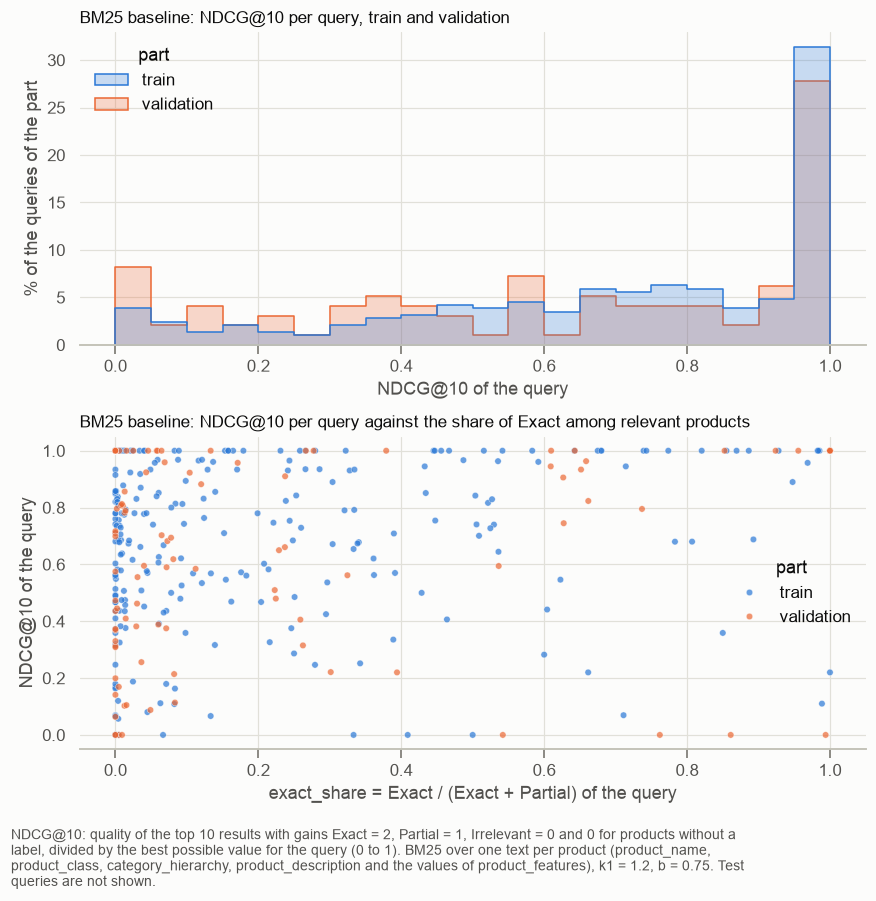

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(8, 7.5))

sns.histplot(data=dev, x="ndcg@10", hue="part", bins=20, binrange=(0, 1), stat="percent",
             common_norm=False, element="step", palette=[plots.SERIES_1, plots.SERIES_2], ax=axes[0])
axes[0].set_title("BM25 baseline: NDCG@10 per query, train and validation")
axes[0].set_xlabel("NDCG@10 of the query")
axes[0].set_ylabel("% of the queries of the part")

sns.scatterplot(data=dev, x="exact_share", y="ndcg@10", hue="part", palette=[plots.SERIES_1, plots.SERIES_2],
                s=18, alpha=0.7, ax=axes[1])
axes[1].set_title("BM25 baseline: NDCG@10 per query against the share of Exact among relevant products")
axes[1].set_xlabel("exact_share = Exact / (Exact + Partial) of the query")
axes[1].set_ylabel("NDCG@10 of the query")

fig.tight_layout()
plots.add_caption(fig, (
    "NDCG@10: quality of the top 10 results with gains Exact = 2, Partial = 1, Irrelevant = 0 and 0 for "
    "products without a label, divided by the best possible value for the query (0 to 1). "
    "BM25 over one text per product (product_name, product_class, category_hierarchy, product_description "
    "and the values of product_features), k1 = 1.2, b = 0.75. Test queries are not shown."
))
plt.show()

**Conclusões**

- **`exact_share` tem relação fraca e positiva com o NDCG@10 por query:** correlação de postos de 0,152 em treino e validação juntos (0,105 no treino e 0,275 na validação). A suposição (1) do protocolo aparece, mas fraca. A mediana de `exact_share` é quase igual nas duas partes (0,063 e 0,065), como a estratificação buscava.
- **`n_judged` quase não se relaciona com a nota:** 0,085.
- **`irrelevant_fraction` não se relaciona com a nota:** 0,022. A maior fração de Irrelevant na validação não explica a nota menor dela (3.1).
- **O histograma mostra notas muito espalhadas nas duas partes,** do 0 ao 1, com cerca de 30% das queries perto de 1. A validação tem mais queries perto de 0 (cerca de 8% na faixa de 0 a 0,05, contra 4% no treino), o que puxa a média dela para baixo (3.1). Não sabemos qual característica das queries explica isso.
- **Conclusão para o protocolo:** a estratificação por `exact_share` se justifica pela relação medida, embora fraca. Não vemos motivo para revisá-la antes de usar o teste.

**Suposições**
- A correlação é de um único sistema (BM25). Outro sistema pode ter outra relação com a composição dos `label`.

### 3.4 As queries com a menor nota (treino)

Para começar a análise de erros, listamos as 10 queries de **treino** com o menor NDCG@10, com a composição dos `label` de cada uma.

In [14]:
train_view = dev[dev["part"] == "train"].join(queries.set_index("query_id")["query"])
worst = train_view.nsmallest(10, "ndcg@10")
display(worst[["query", "ndcg@10", "judged@10", "condensed_ndcg@10", "Exact", "Partial", "Irrelevant"]].round(3))

,query,ndcg@10,judged@10,condensed_ndcg@10,Exact,Partial,Irrelevant
query_id,,,,,,,
142,kitchen wooden stand,0.0,0.1,0.189,5,70,128
179,promo codes or discounts,0.0,0.0,0.000,0,1,0
207,dull bed with shirt head board,0.0,0.0,0.359,0,34,0
345,oriental vanity,0.0,0.9,0.000,0,757,391
370,rug for teen room,0.0,0.0,0.000,1,2,0
448,bed side table,0.0,0.0,0.535,81,117,5
452,day bed indian,0.0,0.0,1.000,0,105,0
462,large bases,0.0,0.0,0.000,0,1,1
465,white abstract,0.0,0.0,0.000,1,1,0


**Conclusões**

- **As 10 piores queries de treino têm NDCG@10 = 0, e em 7 delas nenhum dos 10 primeiros tem `label` (judged@10 = 0).** Nesses casos, a nota 0 diz que o BM25 trouxe produtos não julgados, não necessariamente produtos ruins.
- **`bed side table` tem 81 Exact, mas nenhum deles entre os 10 primeiros;** sem os produtos sem `label`, a nota seria 0,535. `day bed indian` teria condensed NDCG@10 = 1,0. São os casos em que a regra "sem `label` = 0" mais pesa.
- **Várias têm pouquíssimos `label`:** `promo codes or discounts`, `large bases`, `white abstract` e `rug for teen room` têm de 1 a 3 produtos julgados. Com tão pouco gabarito, a nota delas é muito instável.
- **`oriental vanity` tem 9 dos 10 primeiros com `label` e nota 0:** todos Irrelevant (a query não tem Exact, só Partial).
- `pedistole sink` aparece aqui, como esperado pela Etapa 2.2.

**Suposições e hipóteses a testar na análise de erros**
- **Hipótese:** em `bed side table`, os Exact podem usar outras palavras, como `bedside` ou `nightstand`, e a tokenização não junta `bed side` em `bedside`. Não conferimos.
- **Hipótese:** em `oriental vanity`, o BM25 pode estar misturando *vanity* de banheiro com penteadeira. Não conferimos.

## Resumo da Etapa 3

- **Baseline BM25 (campo único, `k1 = 1.2`, `b = 0.75`): NDCG@10 de 0,620 na validação [0,555; 0,687]**, MRR@10 de 0,610 e Capped Recall@100 de 0,702. No treino, 0,700, 0,700 e 0,697.
- Um quinto a um quarto dos 10 primeiros não tem `label`. O NDCG@10 sem eles subiria de 0,12 a 0,16; a regra "sem `label` = 0" só pode ser confirmada com um segundo sistema.
- A composição dos `label` quase não explica a nota por query (`exact_share`: 0,152), e a estratificação fica como está.
- As piores queries de treino misturam produtos não julgados no topo, gabaritos muito pequenos e erros de digitação.

**Próximo passo:** ajuste no treino (`k1`, `b` e variantes do texto indexado), medindo só o NDCG@10 médio do treino, e depois uma única rodada na validação com a combinação escolhida.

## Etapa 4 · BM25 v2: texto limpo e plurais

### A escolha e o motivo

A Etapa 1 mostrou dois problemas do texto indexado, e o próprio dataset mostra um terceiro:
- **`yes` e `no`:** cerca de 16% dos tokens do campo único vêm desses valores de `product_features`, e nenhuma query de treino ou validação usa esses tokens (1.3).
- **Números de `product_features`:** sem a chave, `64.7` ou `500` não dizem a que medida se referem, e podem coincidir por acaso com um número da query (1.3).
- **Plurais:** `chairs` não encontra `chair`. O dataset tem `leather chair` e `leather chairs`, e `product_class` usa o plural (`Accent Chairs`, `Benches`, `Mattresses`).

**Escolha:** aplicar de uma vez as três mudanças e medir só o conjunto, sem testar cada uma em separado. É a **BM25 v2**:
1. remoção de plural nos dois lados (queries e produtos), com o *S-stemmer*;
2. em `product_features`, remoção dos valores `yes`/`no` e dos valores só numéricos (`64.7`, `600 ; 276 ; 456`). Os números dos outros campos ficam, porque em `product_name` costumam ser a medida que a query pede (`36" vanity`).

**Motivo principal: restrição de tempo.** São mudanças com motivo claro nos nossos dados, e a melhoria seguinte, o retrieval semântico e o híbrido, deve trazer mais ganho do que ajustes finos do texto. Medir cada mudança em separado custaria mais trabalho para nós e para quem revisa, para responder perguntas de pouco impacto. As escolhas foram feitas antes de ver qualquer número da v2.

**Por que só plurais, e não um stemmer completo:** um stemmer completo (Porter, Snowball) junta também `dining` e `dine`, `living` e `live`, o que mistura sentidos num catálogo de móveis. O *S-stemmer* só trata plurais.

**Uma regra nossa no S-stemmer:** a versão original transforma `mattresses` em `mattresse` e `benches` em `benche`, que não batem com `mattress` e `bench`. Cerca de 1.000 valores de `product_class` têm plurais desse tipo (`boxes`, `benches`, `mattresses`, `dishes`). Acrescentamos uma regra, verificada antes das outras: *-es* depois de *ss*, *x*, *z*, *ch* e *sh* é removido. O efeito colateral conhecido é que `niches` vira `nich` e não bate com `niche`; `niche` aparece em 2 valores de `product_name`.

**Num cenário com mais tempo, avaliaríamos:**
- cada mudança em separado (ablação);
- outros stemmers: Porter, Snowball e o de Krovetz, que usa dicionário e é feito para não juntar palavras de sentidos diferentes; e lematização;
- remover números de todos os campos, ou tratá-los como medidas;
- trocar `chave : yes` pela chave (`headboard : yes` vira `headboard`), em vez de só remover;
- o retrieval por campo (BM25F ou soma ponderada).

**Fontes externas** (separadas do que os nossos dados mostram):
- Harman, *How effective is suffixing?*, JASIS 42(1), 1991 ([DOI](https://doi.org/10.1002/(sici)1097-4571(199101)42:1%3C7::aid-asi2%3E3.0.co;2-p)): define o *S-stemmer* e compara três algoritmos de sufixo em três coleções, sem melhora significativa em nenhum. Não conseguimos abrir o texto completo; as regras seguem a descrição usual do algoritmo.
- Hull, *Stemming algorithms: a case study for detailed evaluation*, JASIS 47(1), 1996 ([RePEc](https://ideas.repec.org/a/bla/jamest/v47y1996i1p70-84.html)): avalia stemmers query a query. Não lemos o texto nesta sessão.
- A literatura não garante ganho com stemming; a nossa justificativa é o problema de plural visível nos nossos dados, e a medição abaixo diz se ajudou.

### 4.1 O efeito no texto indexado

In [15]:
v2_tokens = retrieval.single_field_tokens(products, **retrieval.V2_TEXT)
baseline_tokens = build_tokens

text_effect = pd.DataFrame({
    "baseline": [baseline_tokens.map(len).median(), baseline_tokens.map(len).sum(), len({t for ts in baseline_tokens for t in ts})],
    "v2": [v2_tokens.map(len).median(), v2_tokens.map(len).sum(), len({t for ts in v2_tokens for t in ts})],
}, index=["median tokens per product", "total tokens", "vocabulary"])
text_effect["change_pct"] = (text_effect["v2"] / text_effect["baseline"] - 1) * 100
display(text_effect.round(1))

examples = ["leather chairs", "mattresses", "wood benches", "36 inch vanity"]
display(pd.DataFrame({"query": examples,
                      "baseline_tokens": [text.tokenize(e) for e in examples],
                      "v2_tokens": [text.tokenize(e, stem=True) for e in examples]}))

,baseline,v2,change_pct
median tokens per product,159.0,120.0,-24.5
total tokens,7204605.0,5523197.0,-23.3
vocabulary,54416.0,48185.0,-11.5


,query,baseline_tokens,v2_tokens
0,leather chairs,"[leather, chairs]","[leather, chair]"
1,mattresses,[mattresses],[mattress]
2,wood benches,"[wood, benches]","[wood, bench]"
3,36 inch vanity,"[36, inch, vanity]","[36, inch, vanity]"


**Conclusões**

- **O texto indexado encolhe cerca de um quarto:** a mediana passa de 159 para 120 tokens por produto (−24,5%), e o total de tokens cai 23,3%. O vocabulário cai 11,5% (de 54.416 para 48.185), porque singular e plural viram um só token.
- **Os exemplos se comportam como esperado:** `chairs`, `mattresses` e `benches` viram `chair`, `mattress` e `bench`; `36 inch vanity` não muda, porque números fora de `product_features` são mantidos.

### 4.2 Ajuste de `k1` e `b` no treino

A grade foi fixada antes de rodar (`docs/EVALUATION.md`): `k1` em {0,6; 0,9; 1,2; 1,5; 2,0} e `b` em {0,3; 0,5; 0,75; 0,9}, só no texto da v2, nas 287 queries de treino. Fica a combinação de maior Capped Recall@100 (só Exact); se a diferença para a melhor for menor que 0,005, desempata o NDCG@10. O valor do vencedor no treino sai otimista, porque foi o melhor entre 20, e não entra na comparação.

In [16]:
train_queries = evaluate.split_queries(queries, split_by_query, "train")
start = time.perf_counter()
tuning, tuning_per_query = evaluate.tune_bm25(v2_tokens, stem=True, queries=train_queries, labels=labels_by_query)
print(f"grid of {len(tuning)} combinations in {time.perf_counter() - start:.0f} s")

display(tuning.pivot(index="k1", columns="b", values="capped_recall@100").round(3))
display(tuning.pivot(index="k1", columns="b", values="ndcg@10").round(3))
chosen = evaluate.select_tuned(tuning)
chosen_key = (float(chosen["k1"]), float(chosen["b"]))
print(f"chosen: k1 = {chosen_key[0]}, b = {chosen_key[1]} | train capped_recall@100 = {chosen['capped_recall@100']:.3f}, ndcg@10 = {chosen['ndcg@10']:.3f}")

grid of 20 combinations in 139 s


b,0.30,0.50,0.75,0.90
k1,,,,
0.6,0.725,0.722,0.723,0.720
0.9,0.734,0.729,0.724,0.722
1.2,0.736,0.731,0.726,0.720
1.5,0.731,0.724,0.722,0.717
2.0,0.729,0.725,0.721,0.715


b,0.30,0.50,0.75,0.90
k1,,,,
0.6,0.701,0.705,0.704,0.691
0.9,0.712,0.715,0.713,0.700
1.2,0.715,0.721,0.719,0.706
1.5,0.719,0.724,0.722,0.710
2.0,0.723,0.729,0.724,0.708


chosen: k1 = 1.2, b = 0.5 | train capped_recall@100 = 0.731, ndcg@10 = 0.721


Para saber se as diferenças da grade são maiores que o ruído da amostra de queries, comparamos cada combinação com a escolhida, query a query, com o bootstrap pareado (diferença = combinação − escolhida, intervalo de 95%, treino).

In [17]:
grid_rows = []
for key, table in tuning_per_query.items():
    if key == chosen_key:
        continue
    row = {"k1": key[0], "b": key[1]}
    for metric in ["capped_recall@100", "ndcg@10"]:
        difference = evaluate.paired_bootstrap(table, tuning_per_query[chosen_key], metric)
        row[f"{metric} difference [95% CI]"] = evaluate.format_ci(difference["mean_difference"], difference["ci_low"], difference["ci_high"])
        row[f"{metric} excludes 0"] = difference["ci_low"] > 0 or difference["ci_high"] < 0
    grid_rows.append(row)
grid_differences = pd.DataFrame(grid_rows)
display(grid_differences)
print("combinations with an interval that excludes 0:",
      grid_differences[["capped_recall@100 excludes 0", "ndcg@10 excludes 0"]].sum().to_dict(),
      "of", len(grid_differences))

,k1,b,capped_recall@100 difference [95% CI],capped_recall@100 excludes 0,ndcg@10 difference [95% CI],ndcg@10 excludes 0
0,0.6,0.30,-0.006 [-0.017; 0.008],False,-0.020 [-0.031; -0.009],True
1,0.6,0.50,-0.009 [-0.015; -0.004],True,-0.017 [-0.025; -0.009],True
2,0.6,0.75,-0.008 [-0.014; -0.003],True,-0.018 [-0.027; -0.008],True
3,0.6,0.90,-0.011 [-0.018; -0.004],True,-0.030 [-0.042; -0.018],True
4,0.9,0.30,0.003 [-0.006; 0.016],False,-0.010 [-0.018; -0.002],True
5,0.9,0.50,-0.002 [-0.005; 0.000],False,-0.006 [-0.011; -0.002],True
6,0.9,0.75,-0.007 [-0.012; -0.002],True,-0.009 [-0.016; -0.002],True
7,0.9,0.90,-0.009 [-0.016; -0.003],True,-0.021 [-0.032; -0.011],True
8,1.2,0.30,0.005 [-0.004; 0.017],False,-0.006 [-0.013; 0.000],False
9,1.2,0.75,-0.005 [-0.010; -0.000],True,-0.003 [-0.009; 0.004],False


combinations with an interval that excludes 0: {'capped_recall@100 excludes 0': 12, 'ndcg@10 excludes 0': 11} of 19


**Conclusões**

- **Combinação escolhida: `k1 = 1.2`, `b = 0.5`.** O maior Capped Recall@100 no treino é 0,736 (`k1 = 1.2`, `b = 0.3`). Quatro combinações, incluindo essa, ficam a menos de 0,005 do melhor valor, e entre elas `k1 = 1.2`, `b = 0.5` tem o maior NDCG@10 (0,721), então vence pelo desempate.
- **As diferenças entre combinações são pequenas, mas muitas não são ruído.** Contra a escolhida, a diferença de Capped Recall@100 vai de −0,016 a +0,005, e a de NDCG@10 de −0,030 a +0,007. Mesmo assim, 12 das 19 combinações têm Capped Recall@100 menor com intervalo que exclui 0, e 11 têm NDCG@10 diferente com intervalo que exclui 0. O bootstrap pareado compara as mesmas queries, então detecta diferenças pequenas.
- **As que não se distinguem da escolhida em Capped Recall@100** são principalmente as de `b = 0.3` e as vizinhas; valores altos de `b` (0,9) são piores em quase todas as linhas.
- **Nenhuma combinação supera a escolhida nas duas métricas com intervalo que exclui 0.** A única com NDCG@10 maior e intervalo acima de 0 (`k1 = 2.0`, `b = 0.5`, +0,007) não se distingue em Capped Recall@100.
- **No treino, a mudança de texto pesa mais que `k1` e `b`:** com os valores padrão (`k1 = 1.2`, `b = 0.75`), a v2 tem Capped Recall@100 de 0,726, contra 0,697 do baseline (Etapa 3.1).
- O ajuste levou cerca de 70 s (20 índices, reaproveitando a tokenização).

**Suposições**
- Os valores do treino são otimistas para o vencedor (o melhor entre 20) e servem só para escolher. Os intervalos da segunda tabela também não corrigem para 19 comparações; eles descrevem o tamanho das diferenças, não testam cada uma.

### 4.3 A v2 na validação, contra o baseline

Uma única rodada na validação, com a combinação escolhida no treino. A comparação com o baseline usa o bootstrap pareado sobre as 97 queries de validação (diferença v2 − baseline; intervalo de 95%).

In [18]:
v2_index = retrieval.BM25Index(v2_tokens.index.to_list(), v2_tokens.to_list(),
                               k1=float(chosen["k1"]), b=float(chosen["b"]), stem=True)

def v2_search(query_text: str, k: int) -> list[int]:
    return v2_index.search(query_text, k=k)["product_id"].tolist()

validation_queries = evaluate.split_queries(queries, split_by_query, "validation")
v2_validation = evaluate.evaluate_system(v2_search, validation_queries, labels_by_query)
baseline_validation = per_query["validation"]

metric_names = ["ndcg@10", "mrr@10", "capped_recall@50", "capped_recall@100", "capped_recall@200",
                "judged@10", "condensed_ndcg@10"]
v2_vs_baseline = evaluate.compare_systems(v2_validation, baseline_validation, metric_names, name_a="v2", name_b="baseline")
display(v2_vs_baseline[["baseline_ci", "v2_ci", "difference_ci", "interval_excludes_0", "n_queries",
                        "share_v2_better", "share_baseline_better"]].round(3))
latency = pd.DataFrame({name: table["latency_ms"].quantile([0.5, 0.95]) for name, table in
                        [("baseline", baseline_validation), ("v2", v2_validation)]})
display(latency.rename(index={0.5: "latency_ms_p50", 0.95: "latency_ms_p95"}).round(2))

,baseline_ci,v2_ci,difference_ci,interval_excludes_0,n_queries,share_v2_better,share_baseline_better
ndcg@10,0.620 [0.555; 0.687],0.653 [0.589; 0.718],0.033 [0.014; 0.056],True,97,0.474,0.175
mrr@10,0.610 [0.516; 0.704],0.661 [0.564; 0.752],0.051 [0.013; 0.093],True,77,0.156,0.091
capped_recall@50,0.611 [0.529; 0.692],0.651 [0.572; 0.730],0.041 [0.018; 0.063],True,77,0.377,0.130
capped_recall@100,0.702 [0.626; 0.778],0.705 [0.628; 0.778],0.003 [-0.047; 0.046],False,77,0.364,0.195
capped_recall@200,0.771 [0.705; 0.833],0.786 [0.715; 0.851],0.015 [-0.025; 0.051],False,77,0.312,0.117
judged@10,0.756 [0.695; 0.811],0.782 [0.719; 0.839],0.026 [0.004; 0.050],True,96,0.240,0.125
condensed_ndcg@10,0.781 [0.730; 0.835],0.799 [0.749; 0.851],0.018 [-0.007; 0.044],False,97,0.330,0.206


,baseline,v2
latency_ms_p50,1.71,1.63
latency_ms_p95,6.86,5.23


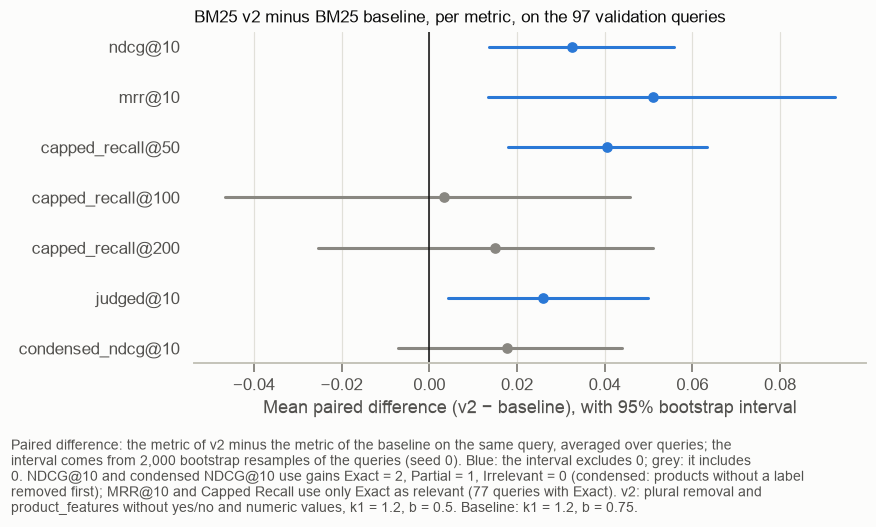

In [19]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
plots.difference_plot(ax, list(v2_vs_baseline.index), v2_vs_baseline["difference"],
                      v2_vs_baseline["difference_ci_low"], v2_vs_baseline["difference_ci_high"])
ax.set_title("BM25 v2 minus BM25 baseline, per metric, on the 97 validation queries")
ax.set_xlabel("Mean paired difference (v2 − baseline), with 95% bootstrap interval")
fig.tight_layout()
plots.add_caption(fig, (
    "Paired difference: the metric of v2 minus the metric of the baseline on the same query, averaged over "
    "queries; the interval comes from 2,000 bootstrap resamples of the queries (seed 0). Blue: the interval "
    "excludes 0; grey: it includes 0. NDCG@10 and condensed NDCG@10 use gains Exact = 2, Partial = 1, "
    "Irrelevant = 0 (condensed: products without a label removed first); MRR@10 and Capped Recall use only "
    "Exact as relevant (77 queries with Exact). v2: plural removal and product_features without yes/no and "
    "numeric values, k1 = 1.2, b = 0.5. Baseline: k1 = 1.2, b = 0.75."
))
plt.show()

**Conclusões**

- **A tabela e o gráfico acima mostram cada métrica com o intervalo de 95% e a diferença pareada v2 − baseline, também com intervalo.**
- **A v2 melhora a ordem do topo na validação:** NDCG@10 de 0,620 para 0,653 (+0,033 [0,014; 0,056]), MRR@10 de 0,610 para 0,661 (+0,051 [0,013; 0,093]) e Capped Recall@50 de 0,611 para 0,651 (+0,041 [0,018; 0,063]). Os três intervalos ficam acima de 0. O NDCG@10 melhora em 47% das queries e piora em 18%.
- **Mas não melhora o Capped Recall@100, a métrica usada no ajuste:** 0,702 para 0,705 (+0,003 [−0,047; 0,046]). O Capped Recall@200 também não muda de forma clara (+0,015 [−0,025; 0,051]). Ou seja, a v2 traz os Exact para posições mais altas dentro dos 100, mas não traz mais Exact para dentro dos 100.
- **Primeira checagem da regra "produto sem `label` = 0":** com produtos sem `label` removidos (condensed NDCG@10), a diferença cai para +0,018 [−0,007; 0,044], e o intervalo passa a incluir 0. A v2 também tem judged@10 maior (+0,026). Parte do ganho de NDCG@10 vem de trazer mais produtos julgados para o topo, e não sabemos se os produtos sem `label` que saíram eram relevantes. A regra não inverte a comparação (v2 continua à frente nas duas versões), mas deixa a vantagem menos segura.
- **A latência não muda de forma relevante** (abaixo de 1 ms no p50 e de 5 ms no p95, como o baseline).

**Suposições**
- O intervalo do bootstrap pareado descreve a incerteza pela amostra de 97 queries de validação. Com 77 queries com Exact, os intervalos do Capped Recall são largos: uma diferença de 0,03 não seria detectada.

## Resumo da Etapa 4

- **A BM25 v2 (plurais + `product_features` sem `yes`/`no` e sem números; `k1 = 1.2`, `b = 0.5`) passa a ser o BM25 de referência:** NDCG@10 de 0,653 na validação [0,589; 0,718], contra 0,620 do baseline; ganho de +0,033 [0,014; 0,056].
- O ganho está na ordem do topo, não na cobertura dos 100 candidatos: o Capped Recall@100 fica em 0,705, praticamente igual.
- **O que isso muda para o próximo passo:** o teto do reranker com BM25 sozinho continua perto de 70% dos Exact nos 100 candidatos. Aumentar a cobertura é o papel do retrieval semântico e do híbrido, que vêm a seguir.
- A escolha de aplicar as três mudanças juntas, sem ablação, foi feita por restrição de tempo; não sabemos qual delas responde pelo ganho.

## Etapa 5 · BM25 v3: a chave dos valores `yes`

A v2 remove `yes` e `no` de `product_features`, e com isso perde a informação de que o produto **tem** a característica: `upholstered : yes` some do texto. A v3 é igual à v2, mas um par com valor `yes` entra pelo texto da chave (`upholstered : yes` vira `upholstered`). `no` e números continuam removidos.

A regra foi registrada no `docs/EVALUATION.md` antes de rodar: mesma grade de `k1` e `b` e mesma regra de escolha da v2, no treino; uma rodada na validação, comparada com a v2 pelo bootstrap pareado.

### 5.1 As chaves com valor `yes`

Antes dos números, olhamos quais chaves entram no texto e quantas coincidem com palavras das queries de treino e validação.

In [20]:
feature_pairs = products["product_features"].map(data.parse_product_features)
yes_keys = pd.Series([key for pairs in feature_pairs for key, value in pairs if value.strip().lower() == "yes"])
dev_query_tokens = {token for tokens in dev_queries["query"].map(lambda q: text.tokenize(q, stem=True)) for token in tokens}
key_tokens = pd.Series([token for key in yes_keys for token in text.tokenize(key, stem=True)])

yes_overview = pd.Series({
    "pairs with value yes": len(yes_keys),
    "distinct keys": yes_keys.nunique(),
    "products with at least one": int(feature_pairs.map(lambda pairs: any(v.strip().lower() == "yes" for _, v in pairs)).sum()),
    "key token occurrences": len(key_tokens),
    "of which also in a train/validation query (%)": round(key_tokens.isin(dev_query_tokens).mean() * 100, 1),
})
display(yes_overview.to_frame("value"))
display(yes_keys.value_counts().head(15).rename("products").to_frame())
display(key_tokens[key_tokens.isin(dev_query_tokens)].value_counts().head(15).rename("occurrences").to_frame())

,value
pairs with value yes,363512.0
distinct keys,2887.0
products with at least one,41594.0
key token occurrences,408616.0
of which also in a train/validation query (%),9.2


,products
productwarranty,22209
adultassemblyrequired,19212
uniformpackagingandlabelingregulationsuplrcompliant,13416
compositewoodproductcwp,9439
carbphaseiicompliantformaldehydeemissions,8150
tscatitlevicompliantformaldehydeemissions,7886
commercialwarranty,7542
installationrequired,7484
upholstered,5468
generalcertificateofconformitygcc,4988


,occurrences
upholstered,5468
non,3718
drawer,2750
wood,2067
leg,1982
headboard,1579
cabinet,1559
shelve,1508
code,1122
shade,1088


**Conclusões**

- **Os valores `yes` são muitos e estão em quase todos os produtos:** 363.512 pares em 41.594 produtos, com 2.887 chaves diferentes.
- **As chaves mais comuns são de garantia e de conformidade, escritas como palavras emendadas:** `productwarranty`, `adultassemblyrequired`, `uniformpackagingandlabelingregulationsuplrcompliant`. A tokenização não separa essas palavras, então elas não coincidem com nenhuma query.
- **Só 9,2% das ocorrências de tokens dessas chaves coincidem com algum token de query de treino ou validação.** As que coincidem são chaves de uma palavra só: `upholstered`, `drawer`, `wood`, `headboard`, `swivel`, `tufted`.
- Por isso, esperamos pouco efeito. A medição está em 5.2.

**Suposições**
- Um token de chave que aparece numa query pode ajudar; um que não aparece em nenhuma query de treino ou validação não muda a nota de nenhuma delas, só o tamanho do texto.

### 5.2 Ajuste no treino e a v3 na validação, contra a v2

In [21]:
v3_tokens = retrieval.single_field_tokens(products, **retrieval.V3_TEXT)
print("median tokens per product: v2", v2_tokens.map(len).median(), "| v3", v3_tokens.map(len).median())

v3_tuning, v3_tuning_per_query = evaluate.tune_bm25(v3_tokens, stem=True, queries=train_queries, labels=labels_by_query)
v3_chosen = evaluate.select_tuned(v3_tuning)
v3_key = (float(v3_chosen["k1"]), float(v3_chosen["b"]))
print(f"chosen for v3: k1 = {v3_key[0]}, b = {v3_key[1]} | train capped_recall@100 = {v3_chosen['capped_recall@100']:.3f}, ndcg@10 = {v3_chosen['ndcg@10']:.3f}")
display(v3_tuning.pivot(index="k1", columns="b", values="capped_recall@100").round(3))

train_v3_vs_v2 = evaluate.compare_systems(v3_tuning_per_query[v3_key], tuning_per_query[chosen_key],
                                          ["capped_recall@100", "ndcg@10"], name_a="v3", name_b="v2")
print("train, each with its chosen k1 and b (selection-biased, for reference only):")
display(train_v3_vs_v2[["v2_ci", "v3_ci", "difference_ci", "interval_excludes_0"]])

v3_index = retrieval.BM25Index(v3_tokens.index.to_list(), v3_tokens.to_list(), k1=v3_key[0], b=v3_key[1], stem=True)

def v3_search(query_text: str, k: int) -> list[int]:
    return v3_index.search(query_text, k=k)["product_id"].tolist()

v3_validation = evaluate.evaluate_system(v3_search, validation_queries, labels_by_query)
v3_vs_v2 = evaluate.compare_systems(v3_validation, v2_validation, metric_names, name_a="v3", name_b="v2")
print("validation:")
display(v3_vs_v2[["v2_ci", "v3_ci", "difference_ci", "interval_excludes_0", "n_queries", "share_v3_better", "share_v2_better"]].round(3))

median tokens per product: v2 120.0 | v3 129.0


chosen for v3: k1 = 1.2, b = 0.5 | train capped_recall@100 = 0.736, ndcg@10 = 0.721


b,0.30,0.50,0.75,0.90
k1,,,,
0.6,0.722,0.722,0.723,0.721
0.9,0.731,0.729,0.726,0.723
1.2,0.734,0.736,0.726,0.721
1.5,0.729,0.729,0.719,0.718
2.0,0.729,0.730,0.721,0.717


train, each with its chosen k1 and b (selection-biased, for reference only):


,v2_ci,v3_ci,difference_ci,interval_excludes_0
capped_recall@100,0.731 [0.691; 0.770],0.736 [0.696; 0.775],0.005 [-0.003; 0.016],False
ndcg@10,0.721 [0.688; 0.755],0.721 [0.688; 0.755],-0.000 [-0.004; 0.003],False


validation:


,v2_ci,v3_ci,difference_ci,interval_excludes_0,n_queries,share_v3_better,share_v2_better
ndcg@10,0.653 [0.589; 0.718],0.655 [0.591; 0.720],0.002 [-0.004; 0.009],False,97,0.247,0.216
mrr@10,0.661 [0.564; 0.752],0.660 [0.562; 0.749],-0.001 [-0.018; 0.013],False,77,0.052,0.026
capped_recall@50,0.651 [0.572; 0.730],0.659 [0.579; 0.735],0.007 [-0.006; 0.029],False,77,0.130,0.078
capped_recall@100,0.705 [0.628; 0.778],0.710 [0.637; 0.780],0.005 [-0.009; 0.025],False,77,0.078,0.104
capped_recall@200,0.786 [0.715; 0.851],0.775 [0.705; 0.842],-0.011 [-0.038; 0.005],False,77,0.130,0.052
judged@10,0.782 [0.719; 0.839],0.782 [0.719; 0.840],-0.000 [-0.010; 0.008],False,96,0.073,0.052
condensed_ndcg@10,0.799 [0.749; 0.851],0.798 [0.746; 0.851],-0.001 [-0.005; 0.003],False,97,0.155,0.186


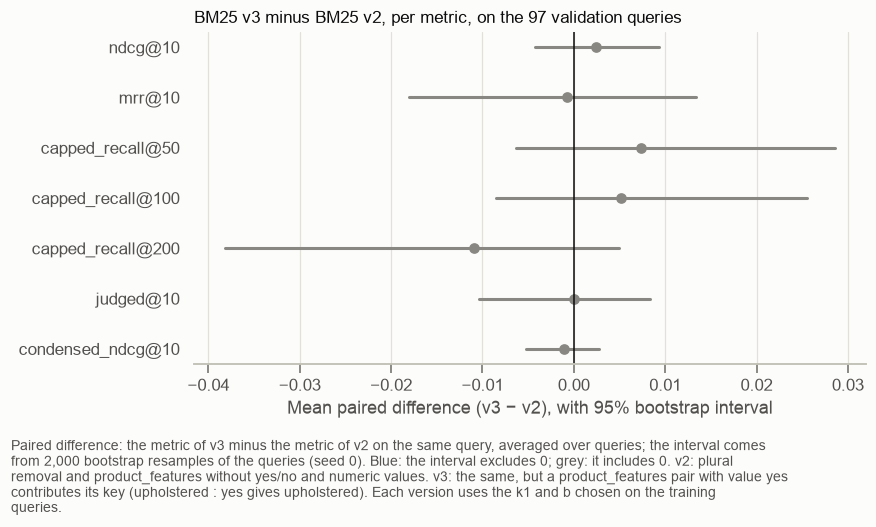

In [22]:
fig, ax = plt.subplots(figsize=(8, 4))
plots.difference_plot(ax, list(v3_vs_v2.index), v3_vs_v2["difference"],
                      v3_vs_v2["difference_ci_low"], v3_vs_v2["difference_ci_high"])
ax.set_title("BM25 v3 minus BM25 v2, per metric, on the 97 validation queries")
ax.set_xlabel("Mean paired difference (v3 − v2), with 95% bootstrap interval")
fig.tight_layout()
plots.add_caption(fig, (
    "Paired difference: the metric of v3 minus the metric of v2 on the same query, averaged over queries; the "
    "interval comes from 2,000 bootstrap resamples of the queries (seed 0). Blue: the interval excludes 0; "
    "grey: it includes 0. v2: plural removal and product_features without yes/no and numeric values. v3: the "
    "same, but a product_features pair with value yes contributes its key (upholstered : yes gives "
    "upholstered). Each version uses the k1 and b chosen on the training queries."
))
plt.show()

**Conclusões**

- **A v3 não se distingue da v2 em nenhuma métrica da validação:** NDCG@10 0,655 contra 0,653 (+0,002 [−0,004; 0,009]); Capped Recall@100 0,710 contra 0,705 (+0,005 [−0,009; 0,025]). Todos os intervalos incluem 0, e o NDCG@10 melhora em 25% das queries e piora em 22%.
- **No treino também não:** com a mesma combinação escolhida (`k1 = 1.2`, `b = 0.5`), Capped Recall@100 +0,005 [−0,003; 0,016] e NDCG@10 sem diferença.
- **O texto fica 7,5% maior** (mediana de 120 para 129 tokens por produto), sem ganho medido.

**Escolha**
- **Mantemos a v2 como o BM25 de referência.** Pela regra de seleção do protocolo, quando o intervalo da diferença inclui 0, fica o sistema mais simples. A v3 fica registrada como testada e sem efeito mensurável.
- **Alternativas não testadas:** separar as chaves emendadas em palavras (`drawersincluded` em `drawers included`), que exigiria uma segmentação de palavras; manter só as chaves de uma palavra.

**Suposições**
- Com 97 queries de validação, diferenças menores que cerca de 0,01 de NDCG@10 não seriam detectadas. "Sem efeito mensurável" quer dizer isso, não que o efeito seja zero.